In [1]:
import pandas as pd
import yaml
import re
import dateparser
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from tqdm import tqdm

In [ ]:
file = "STORE1"

In [3]:
with open(f"{file}/books.yaml", "r") as f:
    data = yaml.load(f, Loader=yaml.FullLoader)

In [4]:
orders = pd.read_parquet(f"{file}/orders.parquet")
users = pd.read_csv(f"{file}/users.csv")
books = pd.DataFrame(data)

In [ ]:
orders.replace(["NULL", "", "NaN", "None", "-", " ", "	"], np.nan, inplace=True)
users.replace(["NULL", "", "NaN", "None", "-", " ", "	"], np.nan, inplace=True)
books.replace(["NULL", "", "NaN", "None", "-", " ", "	"], np.nan, inplace=True)

,:id,:title,:author,:genre,:publisher,:year
0,19437,The Grand Budapest Hotel,"Myles Rohan Sr., Shirl Conn, Rep. Charley Hickle",Suspense/Thriller,Carlton Publishing Group,1980
1,19267,All the King's Men,"Jackie Ondricka, Jewell Harvey JD",Classic,Harvill Press at Random House,1995
2,19428,Once Upon a Time in the West,Sana Marks,Crime/Detective,Legend Books,2004
3,19183,A Swiftly Tilting Planet,Normand Gusikowski,Folklore,NaN,1928
4,19491,WarioWare: Touched!,"Patsy Rice, Leola Mills",Mythopoeia,Eel Pie Publishing,2024
...,...,...,...,...,...,...
745,18998,Dulce et Decorum Est,Edwin Herzog JD,Historical fiction,Hogarth Press,1837
746,18943,Super Mario World,Virgen Goldner,Mythopoeia,Hachette Book Group USA,2018
747,19196,Terrible Swift Sword,Etha Schiller,Fiction narrative,Jarrolds Publishing,2007
748,19132,Star Wars: Episode VI - Return of the Jedi,"Shantell Friesen PhD, Rep. Magda Kemmer, Thers...",Crime/Detective,Bowes & Bowes,1986


In [6]:
books.columns = ["id", "title", "author", "genre", "publisher", "year"]

In [7]:
print(orders.head(10))
print(orders.dtypes)

      id  user_id  book_id  quantity unit_price                 timestamp  \
0  70365    51860    19516         1     $55¢50         20:13,31-May-2026   
1  75931    52316    19014         2    $ 50.75  01:08:20 P.M.;2025-12-28   
2  75546    54009    19457         1     $23.75    08:00:36 AM;2025-11-13   
3  74431    53245    19161         1    30.25 €   19:39:13 14-August-2025   
4  74204    51627    19108         1   48.50USD         09:46,26-Jul-2025   
5  71334    52620    19131         1   USD 22.5       2026-06-22,13:21:39   
6  71634    51279    19408         3       63.$       2025-12-11T02:01:49   
7  77031    53261    19092         1     $28¢00       2026-06-17T02:46:46   
8  74169    53865    19148         1   EUR 46.5  21-OCT-2025, 09:47:23 AM   
9  75249    52387    19261         1   USD22.00          19:59 2025-07-22   

                                            shipping  
0                                                NaN  
1                                         

In [8]:
def convert_price(price):
    if "$" in price or "USD" in price:
        match = re.search(r"\d+\.?\d+", price)
        return float(match.group())

    match = re.search(r"\d+\.?\d+", price)
    return float(match.group()) * 1.2

In [9]:
orders["unit_price"] = orders["unit_price"].apply(convert_price)
orders.rename(columns={"unit_price": "unit_price_USD"}, inplace=True)

orders.head()

,id,user_id,book_id,quantity,unit_price_USD,timestamp,shipping
0,70365,51860,19516,1,55.00,"20:13,31-May-2026",NaN
1,75931,52316,19014,2,50.75,01:08:20 P.M.;2025-12-28,NaN
2,75546,54009,19457,1,23.75,08:00:36 AM;2025-11-13,NaN
3,74431,53245,19161,1,36.30,19:39:13 14-August-2025,"Suite 587 7406 Ahmed Meadows, Spencershire, NM..."
4,74204,51627,19108,1,48.50,"09:46,26-Jul-2025","100 Balistreri Camp, Auerfurt, MO 30489"


In [10]:
orders["timestamp"] = orders["timestamp"].apply(dateparser.parse)
print(orders.head())

      id  user_id  book_id  quantity  unit_price_USD           timestamp  \
0  70365    51860    19516         1           55.00 2026-05-31 20:13:00   
1  75931    52316    19014         2           50.75 2025-12-28 13:08:20   
2  75546    54009    19457         1           23.75 2025-11-13 08:00:36   
3  74431    53245    19161         1           36.30 2025-08-14 19:39:13   
4  74204    51627    19108         1           48.50 2025-07-26 09:46:00   

                                            shipping  
0                                                NaN  
1                                                NaN  
2                                                NaN  
3  Suite 587 7406 Ahmed Meadows, Spencershire, NM...  
4            100 Balistreri Camp, Auerfurt, MO 30489  


In [11]:
print(orders.size)
orders.drop_duplicates(inplace=True)
print(orders.size)

67998
67998


In [12]:
orders["paid_price"] = orders["quantity"] * orders["unit_price_USD"]
orders["date"] = orders["timestamp"].dt.date

In [13]:
orders.head()

,id,user_id,book_id,quantity,unit_price_USD,timestamp,shipping,paid_price,date
0,70365,51860,19516,1,55.00,2026-05-31 20:13:00,NaN,55.00,2026-05-31
1,75931,52316,19014,2,50.75,2025-12-28 13:08:20,NaN,101.50,2025-12-28
2,75546,54009,19457,1,23.75,2025-11-13 08:00:36,NaN,23.75,2025-11-13
3,74431,53245,19161,1,36.30,2025-08-14 19:39:13,"Suite 587 7406 Ahmed Meadows, Spencershire, NM...",36.30,2025-08-14
4,74204,51627,19108,1,48.50,2025-07-26 09:46:00,"100 Balistreri Camp, Auerfurt, MO 30489",48.50,2025-07-26


In [14]:
print(users.head())
print(users.dtypes)

      id                name  \
0  53162       Arnoldo Moore   
1  52237  Kenisha Zemlak Sr.   
2  53589          Floy Kling   
3  54329       Desmond Adams   
4  53290        Torrie Sipes   

                                             address           phone  \
0  Suite 617 27446 Tremblay Divide, Gislasonside,...  (988) 724-0521   
1             2634 Fahey Forks, East Vance, CO 54477  (939) 148-2312   
2                                                NaN  (724) 943-2841   
3  Apt. 594 4933 Walsh Vista, West Brandenside, L...    336.384.0025   
4   Apt. 442 4822 Sid Plaza, Dietrichhaven, TN 67794  (816) 522-3840   

                                email  
0         guy.jacobson@schumm.example  
1  marshall_johnston@homenick.example  
2                   kurtis@stehr.test  
3       joannie.larson@gulgowski.test  
4              earl_moen@flatley.test  
id         int64
name         str
address      str
phone        str
email        str
dtype: object


In [15]:
def convert_phone(phone):
    match = re.search(r"(\d+)[^\d]*(\d+)[^\d]*(\d+)", phone)

    return "".join(match.groups())

In [16]:
users["phone"] = users["phone"].apply(convert_phone)

In [17]:
print(users.size)
users.drop_duplicates(subset=["name", "address", "phone", "email"], inplace=True)
print(users.size)

15790
15790


In [18]:
print(books.head())
print(books.dtypes)

      id                         title  \
0  19437      The Grand Budapest Hotel   
1  19267            All the King's Men   
2  19428  Once Upon a Time in the West   
3  19183      A Swiftly Tilting Planet   
4  19491           WarioWare: Touched!   

                                             author              genre  \
0  Myles Rohan Sr., Shirl Conn, Rep. Charley Hickle  Suspense/Thriller   
1                 Jackie Ondricka, Jewell Harvey JD            Classic   
2                                        Sana Marks    Crime/Detective   
3                                Normand Gusikowski           Folklore   
4                           Patsy Rice, Leola Mills         Mythopoeia   

                       publisher  year  
0       Carlton Publishing Group  1980  
1  Harvill Press at Random House  1995  
2                   Legend Books  2004  
3                            NaN  1928  
4             Eel Pie Publishing  2024  
id            int64
title           str
author          

In [19]:
books["year"] = pd.to_numeric(books["year"], errors="coerce")
books["year"] = books["year"].where(books["year"] > 0, np.nan)
books["year"] = books["year"].astype("Int32")

In [20]:
print(books.size)
books.drop_duplicates(subset=["title", "author", "genre", "publisher", "year"], inplace=True)
print(books.size)

4500
4500


In [21]:
users.to_csv(f"{file}/clean/users.csv", index=False)
books.to_csv(f"{file}/clean/books.csv", index=False)
orders.to_csv(f"{file}/clean/orders.csv", index=False)

In [22]:
orders["daily_revenue"] = orders.groupby("date")["paid_price"].transform("sum").round(2)
best_days = orders[["date", "daily_revenue"]].drop_duplicates().sort_values("daily_revenue", ascending=False).head(5)
best_days.to_csv(f"{file}/best_days", index=False)
print(best_days)

           date  daily_revenue
235  2025-10-20        3490.65
28   2025-11-28        3266.02
76   2025-09-27        3187.10
66   2025-09-11        3177.18
388  2025-10-17        3160.69


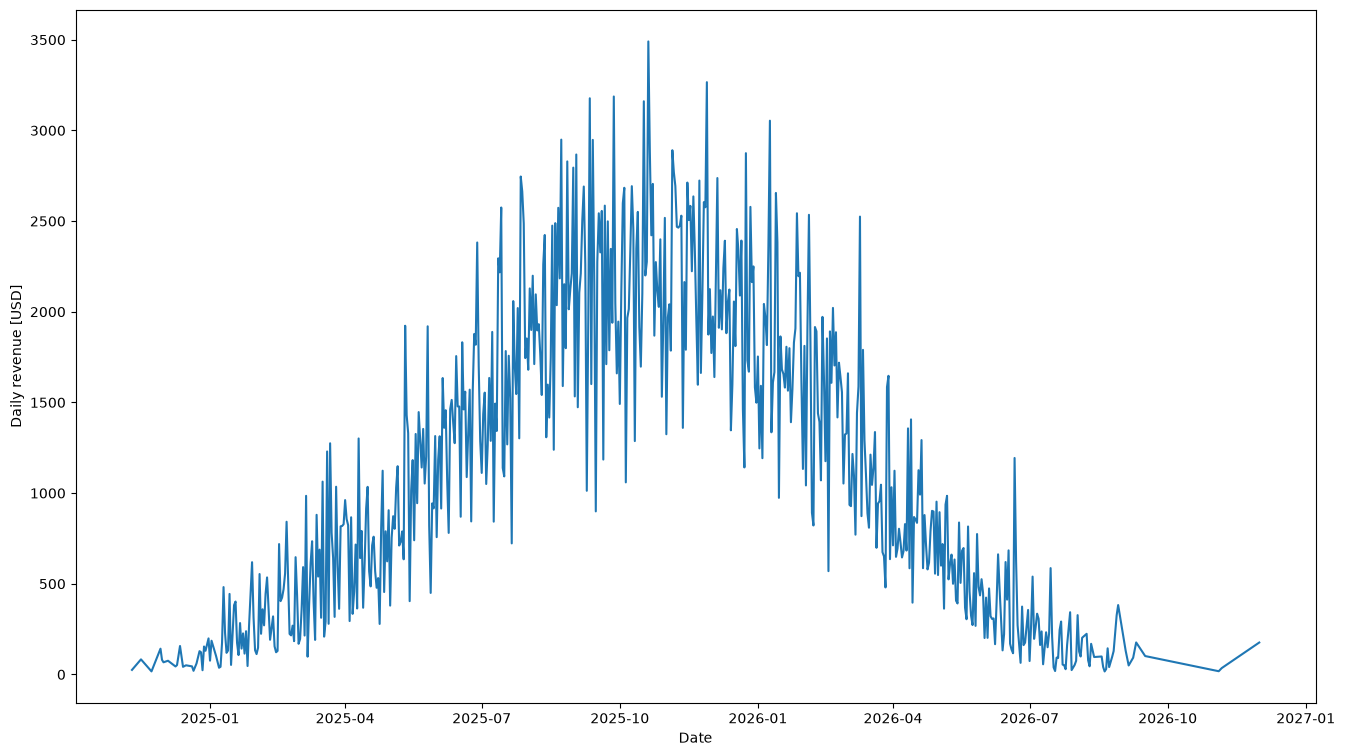

In [23]:
order_to_plot = orders[["date", "daily_revenue"]].drop_duplicates().sort_values("date")

plt.figure(figsize=(16, 9))
plt.plot(order_to_plot["date"], order_to_plot["daily_revenue"])
plt.xlabel("Date")
plt.ylabel("Daily revenue [USD]")
plt.savefig(f"{file}/{file}_fig")
plt.show()


In [24]:
books["author_set"] = books["author"].apply(
    lambda x: frozenset(name.strip() for name in str(x).split(","))
)

In [25]:
orders_and_books = pd.merge(books, orders, "inner", left_on="id", right_on="book_id")

author_revenue = orders_and_books.groupby(["author_set"])["paid_price"].aggregate("sum").round(2).sort_values(ascending=False)
print(author_revenue)

author_set
frozenset({Dulcie Bode})                                                9542.33
frozenset({Cletus Parker, Ira Osinski})                                 8159.11
frozenset({Beverly Heaney})                                             6405.42
frozenset({Prof. Dorine Stracke})                                       6296.66
frozenset({Carey Lubowitz})                                             6036.64
                                                                         ...   
frozenset({Zona Purdy, Nieves Rempel, Mirella Lueilwitz})                264.29
frozenset({Tammi Kunde, Zulema Botsford, Mrs. Mariko Runolfsdottir})     220.16
frozenset({Msgr. Preston Bergnaum})                                      207.14
frozenset({Theron Volkman})                                              184.54
frozenset({Tomi Mosciski})                                               175.18
Name: paid_price, Length: 311, dtype: float64


In [26]:
users_accounts = {}
G = nx.Graph()
G.add_nodes_from(users["id"])

for i in tqdm(range(users.shape[0])):
    for j in range(i + 1, users.shape[0]):
        different_columns = 0
        
        for col_i, col_j in zip(users.iloc[i][1:], users.iloc[j][1:]): 
            if col_i != col_j:
                different_columns += 1

            if different_columns > 1:
                break
        else:
            G.add_edge(users.iat[i, 0], users.iat[j, 0])

unique_accounts = list(nx.connected_components(G))

100%|██████████| 3158/3158 [23:32<00:00,  2.23it/s]


In [27]:
spendings = {}

for ids in unique_accounts:
    ids_tuple = tuple(ids)
    spendings[ids_tuple] = 0

    for id in ids_tuple:
        spendings[ids_tuple] += orders[orders["user_id"] == id]["paid_price"].sum()


best_buyer = sorted(spendings, key=spendings.get, reverse=True)[0]
best_buyer_str = "; ".join(str(int(i)) for i in best_buyer)

In [28]:
with open(f"{file}/summary.csv", "w") as f:
    f.writelines(["unique_users_count, unique_authors_count, best_author, best_customer\n",
    f"{len(unique_accounts)}, {books["author_set"].nunique()}, {next(iter(author_revenue.index[0]))}, {best_buyer_str}"])